In [2]:
  !pip install numpy matplotlib

In [3]:
import math 
import numpy as np 
import matplotlib.pyplot as plt
%matplotlib inline

In [4]:
def f(x): 
    return 3*x**2 - 4*x + 5

In [5]:
f(3.0)

20.0

In [6]:
xs = np.arange(-5, 5, 0.25)
xs


array([-5.  , -4.75, -4.5 , -4.25, -4.  , -3.75, -3.5 , -3.25, -3.  ,
       -2.75, -2.5 , -2.25, -2.  , -1.75, -1.5 , -1.25, -1.  , -0.75,
       -0.5 , -0.25,  0.  ,  0.25,  0.5 ,  0.75,  1.  ,  1.25,  1.5 ,
        1.75,  2.  ,  2.25,  2.5 ,  2.75,  3.  ,  3.25,  3.5 ,  3.75,
        4.  ,  4.25,  4.5 ,  4.75])

In [7]:
ys = f(xs)
ys

array([100.    ,  91.6875,  83.75  ,  76.1875,  69.    ,  62.1875,
        55.75  ,  49.6875,  44.    ,  38.6875,  33.75  ,  29.1875,
        25.    ,  21.1875,  17.75  ,  14.6875,  12.    ,   9.6875,
         7.75  ,   6.1875,   5.    ,   4.1875,   3.75  ,   3.6875,
         4.    ,   4.6875,   5.75  ,   7.1875,   9.    ,  11.1875,
        13.75  ,  16.6875,  20.    ,  23.6875,  27.75  ,  32.1875,
        37.    ,  42.1875,  47.75  ,  53.6875])

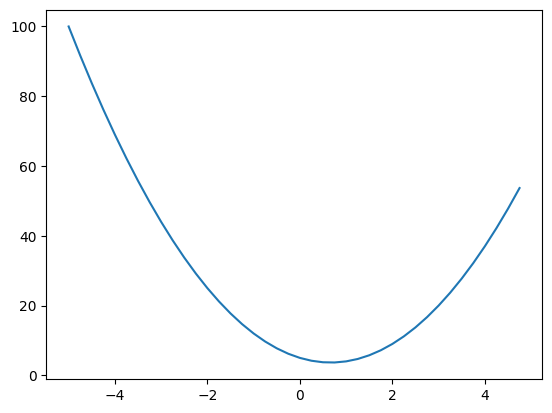

In [8]:
plt.plot(xs, ys)

In [9]:
# Now we need to find the derivative of any given point on this plot
# So we are just going to look at the definition of derivative
# At any given x, if you slighly increase is by small number h, how much the slop of that change would change

In [10]:
h = 0.00000001
x = -3.0
f(x + h)

43.999999779999996

In [11]:
# by how much the function changed based on h
# So basically this is the slop of x, which is means how differential x is
# L=\lim _{h\to 0}{\frac {f(a+h)-f(a)}{h}}} 
(f(x + h) - f(x)) / h

-22.00000039920269

In [12]:
# at roughly 2/3 the derivative would be 0 which means the function does not respond and stays the same

In [13]:
# lets get more complex
a = 2.0
b = -3.0
c = 10.0
d = a*b + c 
print(d)

4.0


In [14]:
h = 0.0001

# inputs
a = 2.0
b = -3.0
c = 10.0

d1 = a*b + c 
# now derivative of d1 with respect to h
a += h
d2 = a*b + c

print('d1', d1)
print('d2', d2)

# the derivative: how much did the slope get increase/decreased when we bumped it by h, normalized by h itself
print('slope', (d2 - d1)/h)

d1 4.0
d2 3.999699999999999
slope -3.000000000010772


In [15]:
# Now we move on to NN 
# We need to create data structures to build out these mathematical expressions in NN

class Value:
    def __init__(self, data, _children=(), _op='', label=''):
        self.data = data
        self.grad = 0.0 # grad holds the derivative of L with respect to this node's value
        self._backward = lambda: None
        self._prev = set(_children)
        self._op = _op
        self.label = label

    def __repr__(self):
        return f"Value(data={self.data})"

    def __add__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data + other.data, (self, other), '+')

        def _backward(): 
            self.grad += 1.0 * out.grad
            other.grad += 1.0 * out.grad
        out._backward = _backward
        return out

    def __radd__(self, other):
        return self + other

    def __neg__(self): 
        return self * -1

    def __sub__(self, other): 
        return self + (-other)

    def __rsub__(self, other): 
        return self + (-other)

    def __mul__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data * other.data, (self, other), '*')

        def _backward():
            self.grad += other.data * out.grad
            other.grad += self.data * out.grad
        out._backward = _backward
        return out

    def __rmul__(self, other):
        return self * other

    def __pow__(self, other): 
        assert isinstance(other, (int, float)), "Only supporting int/float powers for now"
        out = Value(self.data**other, (self, ), f'**{other}')

        def _backward():
            self.grad += other * (self.data ** (other -1)) * out.grad
        out._backward = _backward

        return out

    def __truediv__(self, other): # self/other
        return self * other**-1 # we devide it that way so we don't have to redefine backward and gradient by reusing __mul__

    def exp(self):
        # 5 (e^5)
        x = self.data 
        out = Value(math.exp(x), (self, ), 'exp')

        def _backward(): 
            self.grad += out.data * out.grad
        out._backward = _backward

        return out
        
    def tanh(self):
        x = self.data
        t = (math.exp(2*x) - 1) / (math.exp(2*x) + 1)
        out = Value(t, (self, ), 'tanh')
        
        def _backward():
            self.grad += (1.0 - t**2) * out.grad
        out._backward = _backward
        return out

    def backward(self): 
        topo = []
        visited = set() 
        def build_topo(v):
            if v not in visited: 
                visited.add(v)
                for child in v._prev: 
                    build_topo(child)
                topo.append(v)

        self.grad = 1.0
        build_topo(self)
        for node in reversed(topo): 
            node._backward()

In [16]:
p = Value(2.0) 
z = Value(4.0)


In [17]:
a = Value(2.0, label='a')
b = Value(-3.0, label='b')
c = Value(10, label='c')
e = a*b; e.label = 'e'
d = e + c; d.label = 'd'
f = Value(-2.0, label='f')
L = d*f; L.label = 'L'
L

Value(data=-8.0)

In [18]:
!pip install graphviz

In [19]:
# visualize the nodes in a grapph 

from graphviz import Digraph

def trace(root): 
    nodes, edges = set(), set()
    def build(v): 
        if v not in nodes: 
            nodes.add(v)
            for child in v._prev: 
                edges.add((child, v))
                build(child)
    build(root)
    return nodes, edges

def draw_dot(root):
    dot = Digraph(format='svg', graph_attr={'rankdir': 'LR'})

    nodes, edges = trace(root)
    for n in nodes: 
        uid = str(id(n))
        # for any value in the graph create a rectangular ('record') node for it
        dot.node(name = uid, label =  "{ %s | data %.4f | grad %.4f}" % (n.label, n.data, n.grad), shape='record')
        if n._op: 
            # if this node is a result of an op, create a op node for it
            dot.node(name=uid + n._op, label=n._op)
            # and connect this to the resulting node
            dot.edge(uid + n._op, uid)
            
    for n1, n2 in edges:
        # connect n1 to the op of n2 
        dot.edge(str(id(n1)), str(id(n2)) + n2._op)
    
    return dot

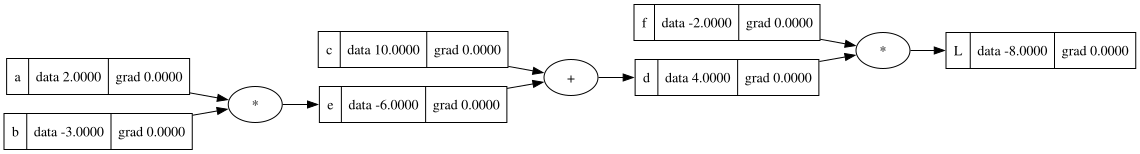

In [20]:
draw_dot(L)
# this right below gives us a forwards pass, which we are passing the data forward

In [21]:
# for backward propogation, we would need to calculate the derivative of L with respect to every other node
# L basically stands for Loss function and the other nodes are just the weights of the nueral network
# we do not want the derivative of L with respect of the data itself because they are fixed values but instead we want 
# the derivative with respect to weights and bisases because we iterate upon them all using the gradient information

In [22]:
# So here is a little exercise
# If L = f * d, then what is dL/dd=?? 
# It's f. Here is how: 

# (f(x + h) - f(x))/h 
# ((d+h)*f - (d*f))/h
# (d*f + h*f - d*f)/h
# h*f/h
# f

In [23]:
L.grad = 1.0
f.grad = 4.0
d.grad = -2.0

# Note: if you change which var you add h to in the function below, you can validate these grad values we hard coded above

In [24]:
# Now that we know the derivatives of f & d we need to find out the next level of node which is e and c 
# Now there is a concept here called local derivative which tells you that when you get the derivative of 

# dL / dc
# We need to use the chain rule here 
# d = c + e
# The chain rule says dL/dc = dL/dd * dd/dc
# We know dL/dd = 1.0 and dd/dc = -2.0; therefore: dL/dc=-2.0 and dL/de=-2.0 because e + c = d. 
c.grad = -2.0
e.grad = -2.0

In [25]:
# In the computation graph, the value e is defined as the result of the multiplication a * b (where e = a * b).

# To calculate the local derivative of e with respect to a (written as de/da), you look at how e changes if you nudge a by a tiny amount. 
# Using the power rule of calculus for the expression a * b:

# When you differentiate a * b with respect to a, the variable b acts as a constant multiplier.
# Therefore, the derivative de/da is simply equal to b.

# dL/da = dL/de * de/da 
# dL/de = -2.0
# e = a * b
# de/da = b
a.grad = -2.0 * -3.0


# now the same thign applies to db
# dL/db = dL/dc * dc/db
# -2.0 * 2.0 

b.grad = (-2.0 * 2.0)

In [26]:
# And Lastly Manual Backpropogation 
a.data += 0.01 * a.grad
b.data += 0.01 * b.grad
c.data += 0.01 * c.grad
f.data += 0.01 * f.grad

e = a * b
d = e + c
L = d * f
print(L.data)

-7.286496


In [27]:
# Here is how you can validate your derrivative calculations by adding the h to different Values and comparing the results

def lol():
    h = 0.001
    a = Value(2.0, label='a')
    b = Value(-3.0, label='b')
    c = Value(10, label='c')
    e = a*b; e.label = 'e'
    d = e + c; d.label = 'd'
    f = Value(-2.0, label='f')
    L = d*f; L.label = 'L'
    L1 = L.data

    a = Value(2.0, label='a')
    b = Value(-3.0, label='b')
    c = Value(10, label='c')
    e = a*b; e.label = 'e'
    d = e + c; d.label = 'd'
    f = Value(-2.0, label='f')
    L = d*f; L.label = 'L'
    L2 = L.data + h

    print((L2 - L1)/h)

lol()

# As you can see below the default base grad of L with respect to L is one. 
# So that's why we have manually started the backprogogation with L.grad = 1 above

1.000000000000334


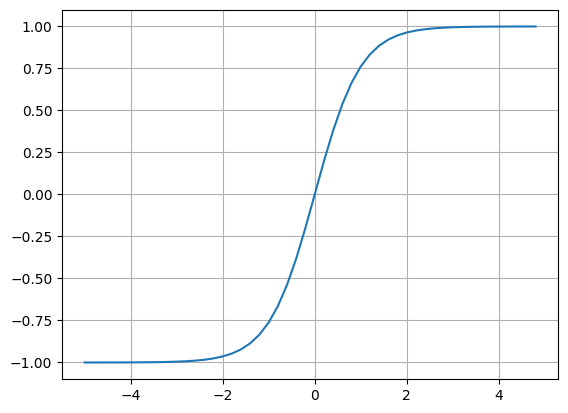

In [28]:
# activation function that keeps the NN output between -1 and 1
plt.plot(np.arange(-5, 5, 0.2), np.tanh(np.arange(-5, 5, 0.2))); plt.grid();

Now let's do auto backgrporpogation with Two Neurons x1,x2 
https://cs231n.github.io/assets/nn1/neuron_model.jpeg
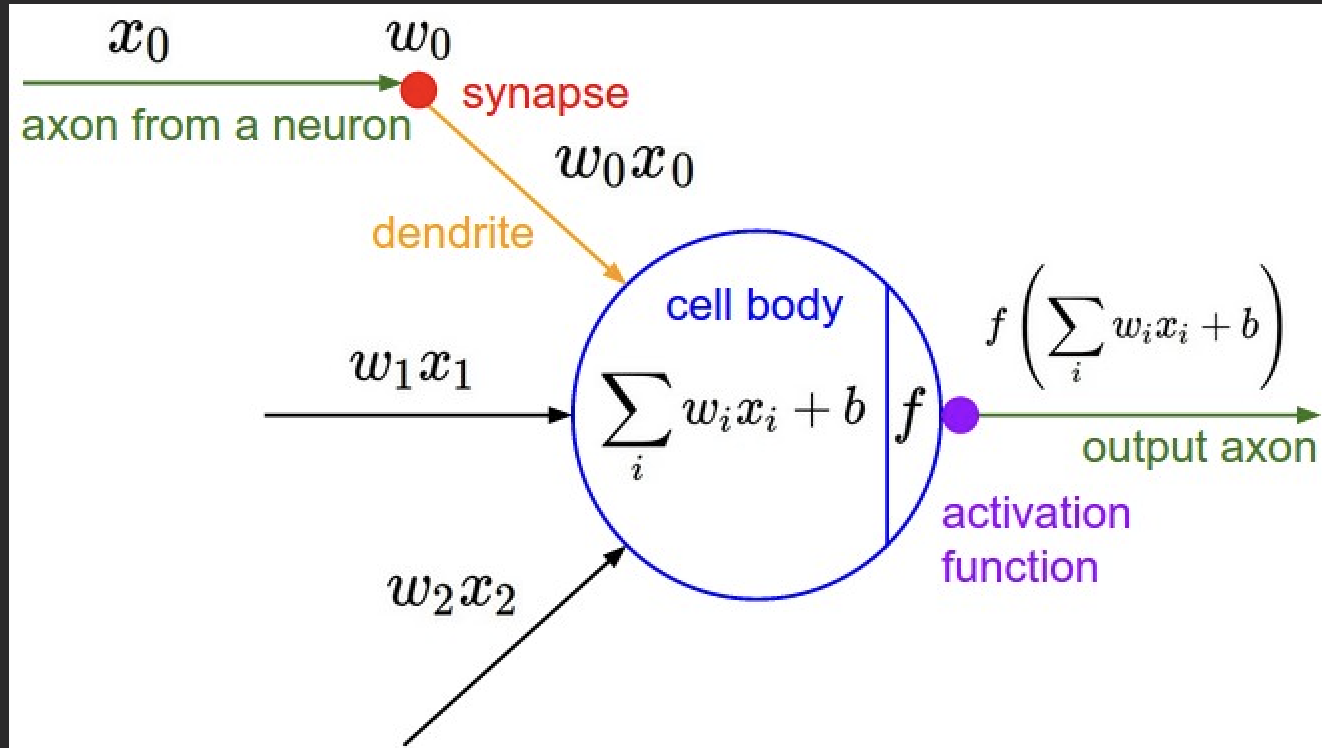

We need to write up this function with out neurons and weights and bisases below

In [29]:
# inputs
x1 = Value(2.0, label='x1')
x2 = Value(0.0, label='x2')
# weights of the neuron
w1 = Value(-3.0, label='w1')
w2 = Value(1.0, label='w2')
# bias of the neuron
b = Value(6.8813735870195432, label='b')
# x1*w1 + x*2w2 + b
x1w1 = x1*w1; x1w1.label = 'x1*w1'
x2w2 = x2*w2; x2w2.label = 'x2*w2'
x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label = 'x1w1 + x2w2'
n = x1w1x2w2 + b; n.label = 'n'
# Now we need to activate n with tanh -> implementation above
o = n.tanh(); o.label = 'o'
o.backward() # for explanation look below

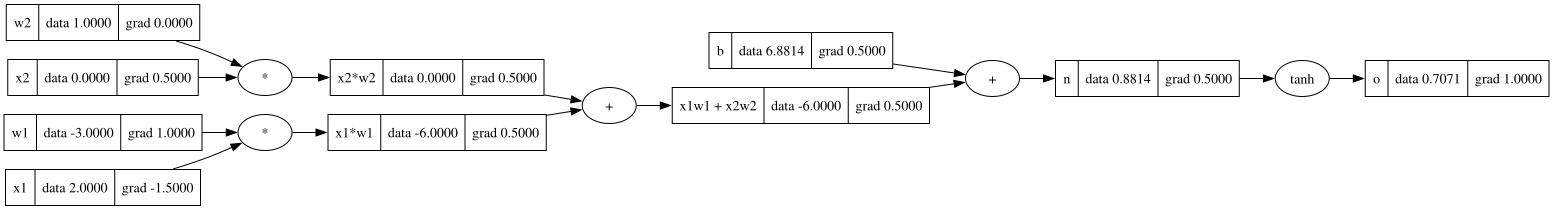

In [30]:
draw_dot(o)

In [31]:
# Now let's start back prop
o.grad = 1.0
# Now the local derivative of tanh is
# do/dn = 1 - tanh(o)**2 -> tanh(o) = 1.0 
# => do/dn = 1 - o**2
n.grad = 1 - o.data**2

The node producing n is the result of adding the neuron's inputs (x1w1 + x2w2 + b). 
Because the local derivative of an addition operation is 1.0 for both inputs, the gradient of 0.5 from the tanh output is simply "routed" or copied directly to the addition nodes.

Result: Therefore, the gradient of 0.5 flows back from the tanh gate and arrives at the sum of the inputs, making the gradient of the intermediate nodes (x1w1, x2w2, and b) equal to 0.5

for the plus the chain rule says just pass it backwards

In [32]:
x1w1x2w2.grad = 0.5
b.grad = 0.5

In [33]:
x1w1.grad = 0.5
x2w2.grad = 0.5

now for the last layer of nuerons x2
So as per chain rule you need to follow the whole path to the o. 
the output 'o' depends on the addition node (let's call the sum 'n') which includes the term 'x2 * w2'.
do/x2 = do/n * dn/dx2w2 * (d(x2w2)/dx2) 
do/dx2 = (gradient of n) * (local derivative of x2w2 with respect to x2).

Since the gradient of 'n' is 0.5 and the local derivative of the multiplication node (x2 * w2) with respect to x2 is w2, the final result is 0.5 * w2.

So, you don't multiply by 0.5 twice; you multiply the incoming gradient (0.5) by the 'w2' weight to get the final gradient for 'x2'.

In [34]:
x2.grad = w2.data * x2w2.grad 
w2.grad = x2.data * x2w2.grad
x1.grad = w1.data * x1w1.grad 
w1.grad = x1.data * x1w1.grad

In [35]:
# Note: we implemented backpropogation in Value so now we can just call:
o.grad = 1.0
o._backward()

In [36]:
n._backward()

In [37]:
b._backward()
# Nothing happens here becase b is a leaf node

In [38]:
x1w1x2w2._backward()

In [39]:
x1w1._backward()
x2w2._backward()

So to avoid calling backward for each node we need to accumulate the grads by doing topological sort

Topological sort is a linear ordering of vertices in a Directed Acyclic Graph (DAG) where for every directed edge mue to v, vertex mue comes before 
. It is primarily used for scheduling tasks, dependency resolution, and detecting cycles. Valid topological sorts only exist for DAGs, and a graph may have multiple valid orderings

https://miro.medium.com/v2/resize:fit:1400/1*uMg_ojFXts2WZSjcZe4oRQ.png
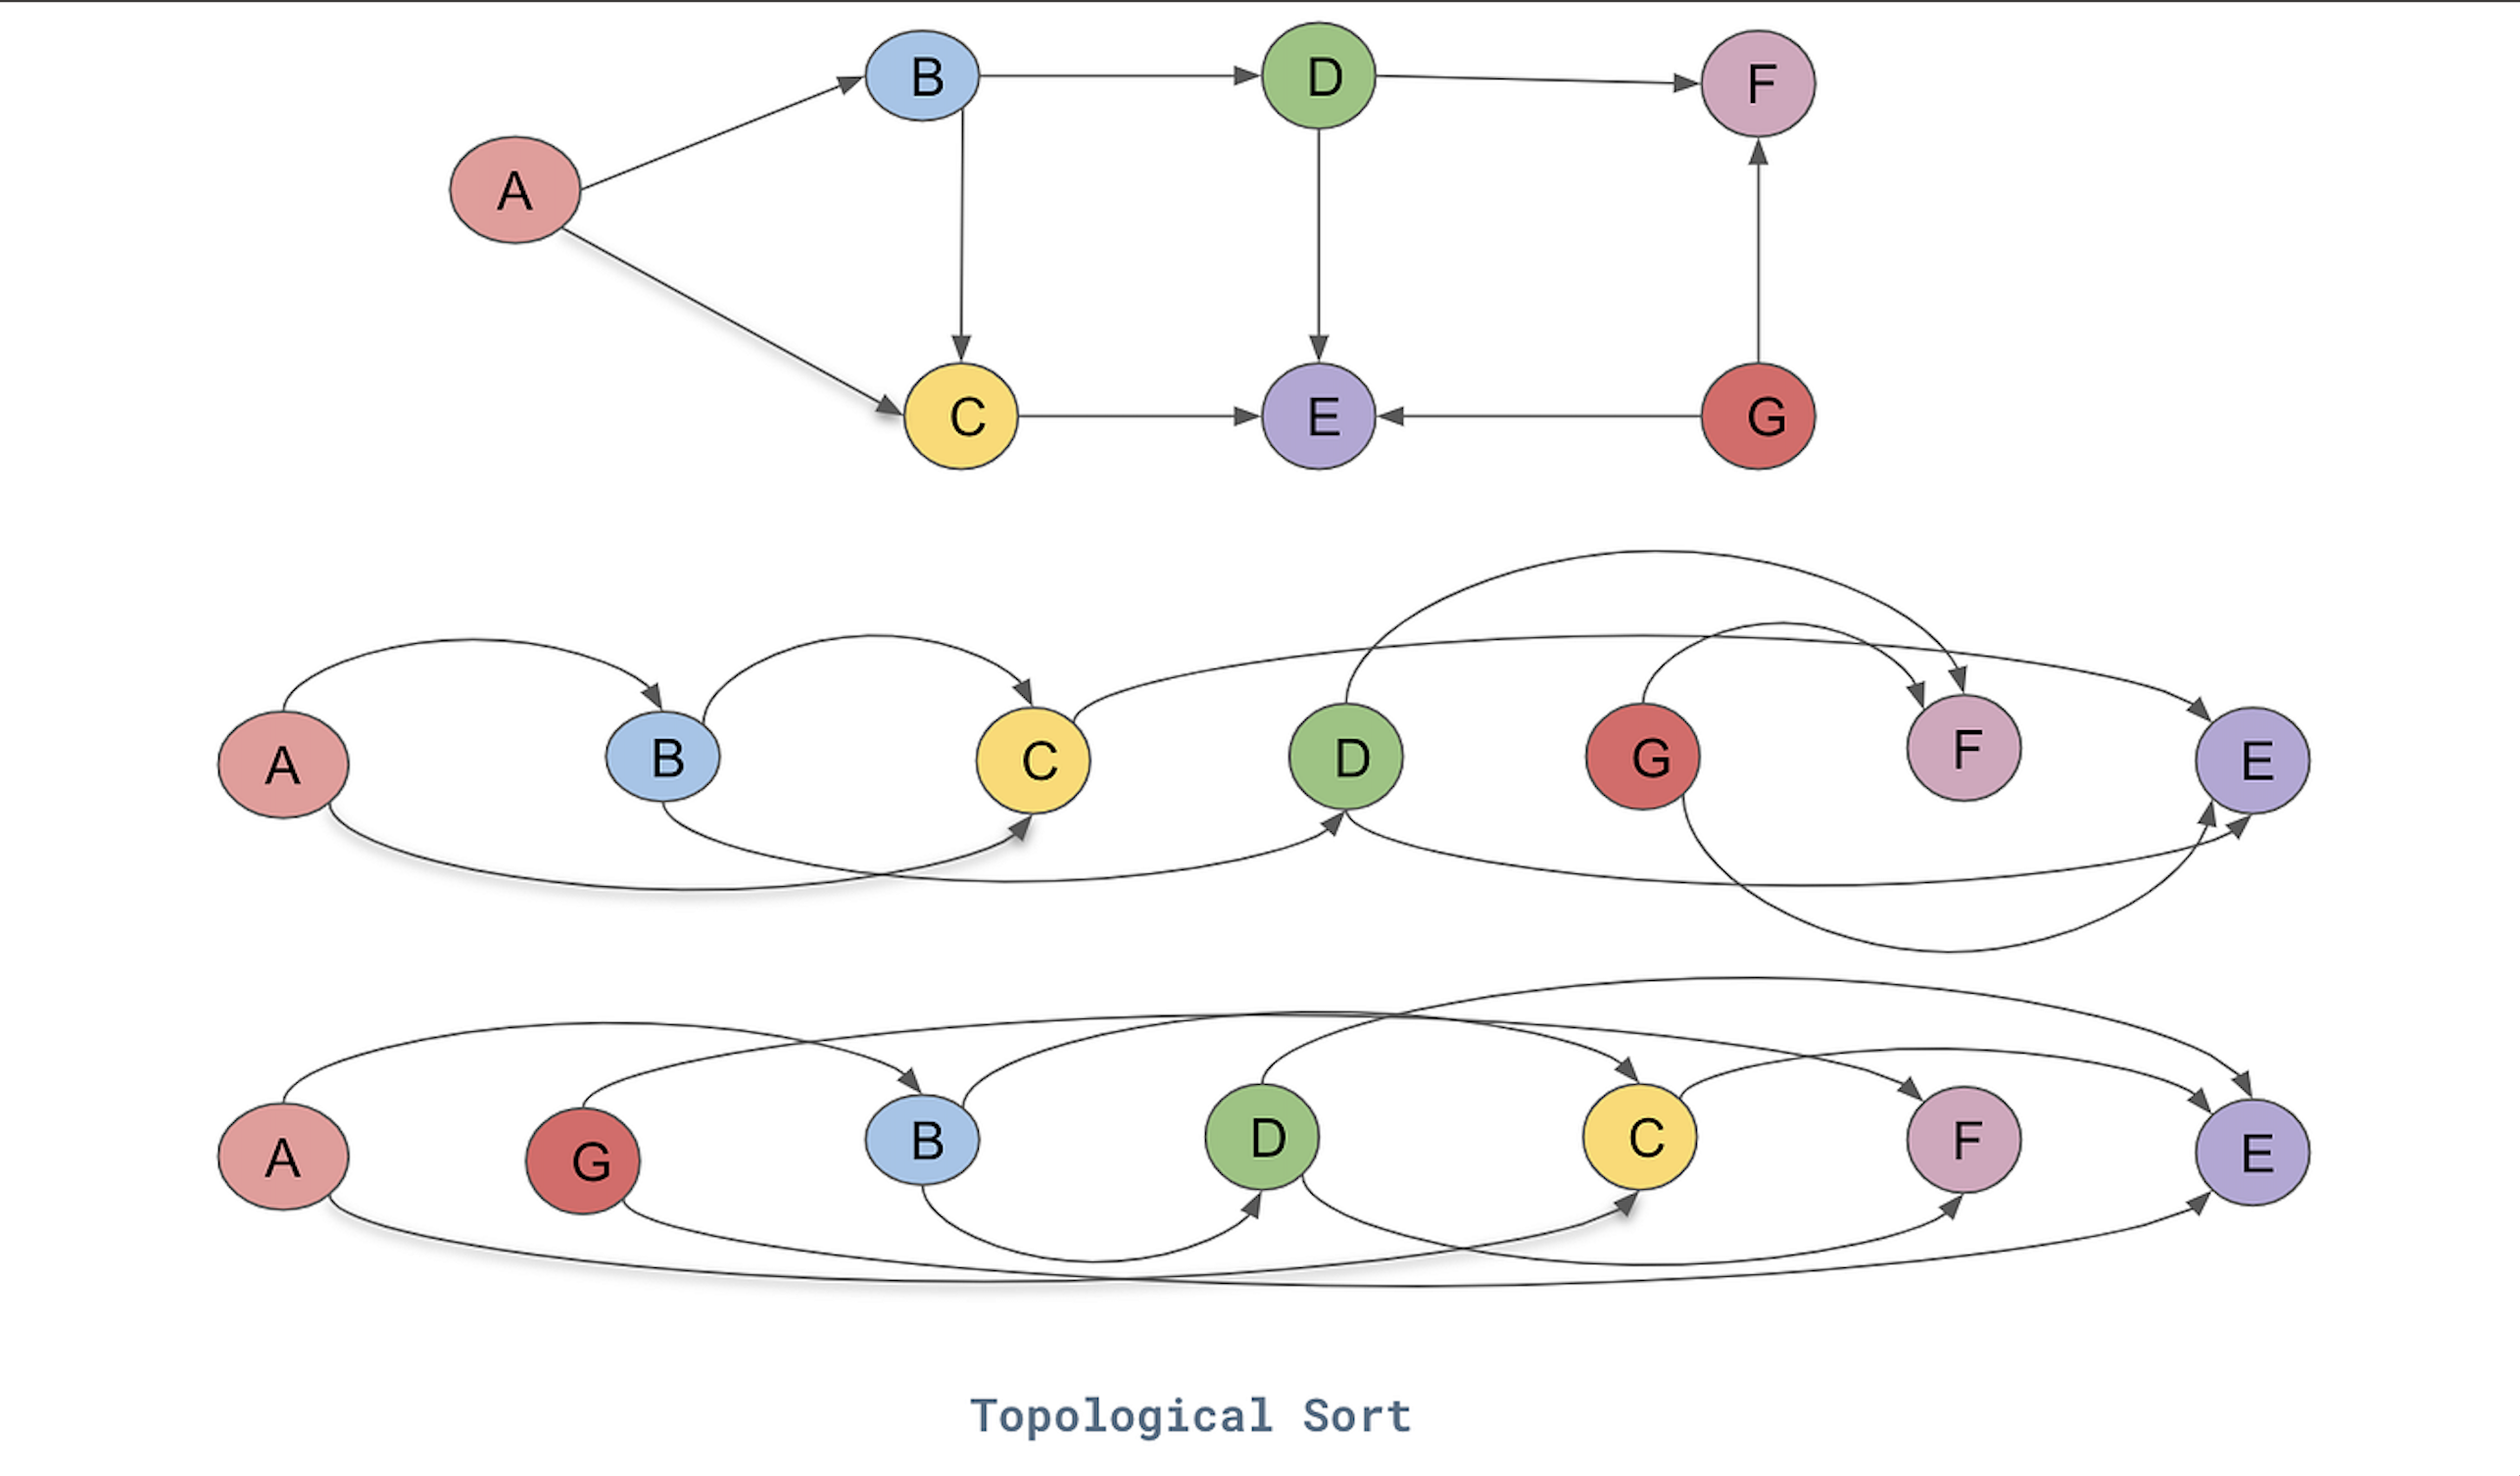

In [40]:
# SO you need to basically add everything from left to right by passing the output which is the right most node
# In otherwords from the last node you iterate to the root node and then start adding them to your topology 

topo = [] 
visited = set()
def build_topo(v): 
    if v not in visited: 
        visited.add(v)
        for child in v._prev:
            build_topo(child) 
        topo.append(v)
build_topo(o) 
topo

[Value(data=6.881373587019543),
 Value(data=1.0),
 Value(data=0.0),
 Value(data=0.0),
 Value(data=-3.0),
 Value(data=2.0),
 Value(data=-6.0),
 Value(data=-6.0),
 Value(data=0.8813735870195432),
 Value(data=0.7071067811865476)]

In [41]:
# so to call the backward autmatically 
o.grad = 1.0
for node in reversed(topo): 
    node._backward()

# Now just put this in the Value object

In [42]:
o.backward()

In [43]:
# But so far we have a serious bug. We do not accumulate the local grad so when we use the same Value node 
# twice, we replace the value to the new local grad instead of accumulating. So instead we need to ad += when assignign grads 
# in backward pass

# the solution is also called the multivariable case in chain rule ;)

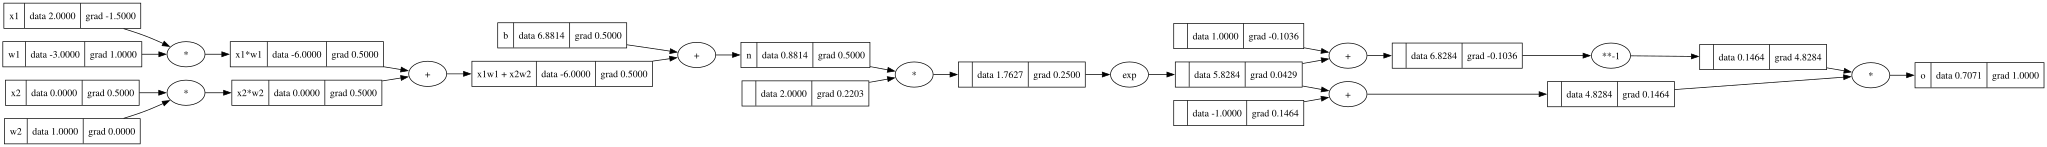

In [44]:
# inputs
x1 = Value(2.0, label='x1')
x2 = Value(0.0, label='x2')
# weights of the neuron
w1 = Value(-3.0, label='w1')
w2 = Value(1.0, label='w2')
# bias of the neuron
b = Value(6.8813735870195432, label='b')
# x1*w1 + x*2w2 + b
x1w1 = x1*w1; x1w1.label = 'x1*w1'
x2w2 = x2*w2; x2w2.label = 'x2*w2'
x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label = 'x1w1 + x2w2'
n = x1w1x2w2 + b; n.label = 'n'
# manual tanh
# ----
e = (2*n).exp()
o = (e-1) / (e+1)
# ----
o.label = 'o'
o.backward() # for explanation look below
draw_dot(o)

In [45]:
# Now let's do the same thing in pytorch
import torch

x1 = torch.Tensor([2.0]).double()                       ; x1.requires_grad = True
x2 = torch.Tensor([0.0]).double()                       ; x2.requires_grad = True
w1 = torch.Tensor([-3.0]).double()                      ; w1.requires_grad = True
w2 = torch.Tensor([1.0]).double()                       ; w2.requires_grad = True
b = torch.Tensor([6.8813735870195432]).double()         ; b.requires_grad = True
n = x1*w1 + x2*w2 + b 
o = torch.tanh(n)

print(o.data.item())
o.backward()

print("---")
print('x2', x2.grad.item())
print('w2', w2.grad.item())
print('x1', x1.grad.item())
print('w1', w1.grad.item())

0.7071066904050358
---
x2 0.5000001283844369
w2 0.0
x1 -1.5000003851533106
w1 1.0000002567688737


In [46]:
# but above example is a simple example of a scalar valued tensor. In pytorch tensors are usually n dimensional arrays of tensors:
import torch
torch.Tensor([[2.0, 3.0, 5.0], [2.0, 4.0, 0.5]]) 

tensor([[2.0000, 3.0000, 5.0000],
        [2.0000, 4.0000, 0.5000]])

In [58]:
import random

class Neuron:

    def __init__(self, nin): 
        self.w = [Value(random.uniform(-1, 1)) for _ in range(nin)]
        self.b = Value(random.uniform(-1, 1))

    def __call__(self, x):
        # w * x + b 
        act = sum((wi*xi for wi, xi in zip(self.w, x)), self.b)
        out = act.tanh()
        return out

    # return parameters of a neuron?? 
    def parameters(self): 
        return self.w + [self.b]

# to forward pass a single Neuron
x = [2.0, 3.0]
n = Neuron(2)
n(x)

Value(data=0.9877919232721087)

In [63]:
# Single Layer

class Layer: 

    def __init__(self, nin, nout): 
        self.neurons = [Neuron(nin) for _ in range(nout)]

    def __call__(self, x): 
        outs = [n(x) for n in self.neurons]
        return outs[0] if len(outs) == 1 else outs

    def parameters(self):
        # Short hand
        return [p for neuron in self.neurons for p in neuron.parameters()]
        # params = [] 
        # for neuron in self.neurons: 
        #     ps = neuron.parameters()
        #     params.extend(ps) 
        # return params

# x = [2.0, 3.0]
# n = Layer(2, 3)
# n(x) 

[Value(data=-0.6445162658303578),
 Value(data=0.9380516515500793),
 Value(data=0.6867381455008469)]

The dashed box represents the Layer object. nin=2 controls how many weights each neuron gets (one per input), and nout=3 controls how many neurons are created. The __call__ just loops over all neurons and collects their outputs into a list — so n(x) returns [out0, out1, out2].

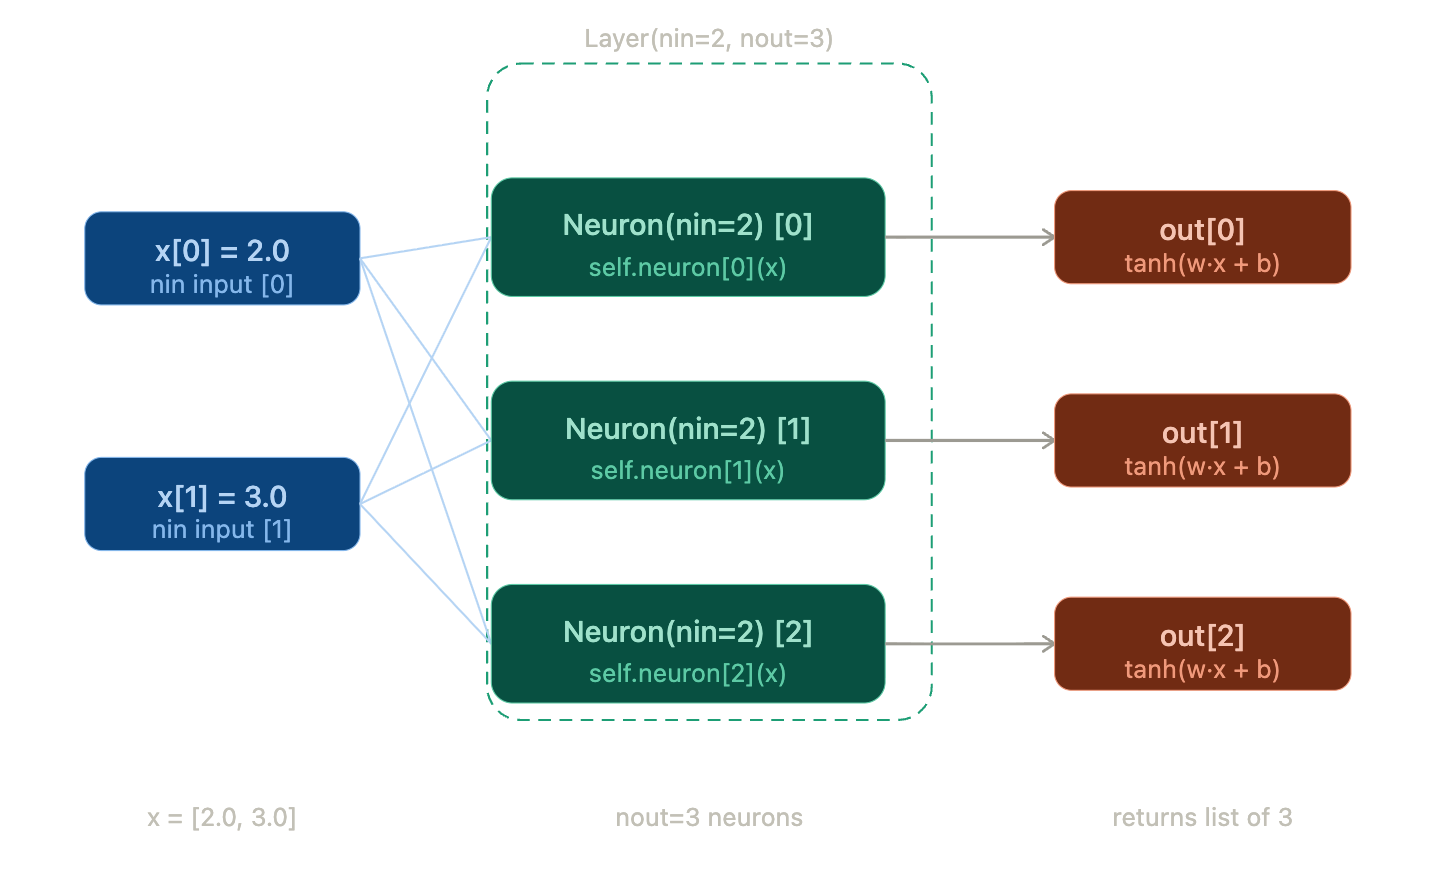

In [64]:
# Multi Layer Perceptron 

class MLP: 
    def __init__(self, nin, nouts): 
        sz = [nin] + nouts
        self.layers = [Layer(sz[i], sz[i+1]) for i in range(len(nouts))]

    def __call__(self, x): 
        for layer in self.layers: 
            x = layer(x)
        return x

    def parameters(self): 
        return [p for layer in self.layers for p in layer.parameters()]


# x = [2.0, 3.0, -1.0]
# n = MLP(3, [4, 4, 1])
# n(x)

Value(data=-0.9433377428966672)

The key insight is the sz = [nin] + nouts trick. For MLP(3, [4, 4, 1]) it builds [3, 4, 4, 1], then creates layers by sliding a window of size 2 across it:

Layer(3, 4) — takes 3 inputs, outputs 4
Layer(4, 4) — takes those 4, outputs 4
Layer(4, 1) — takes those 4, outputs 1 final value

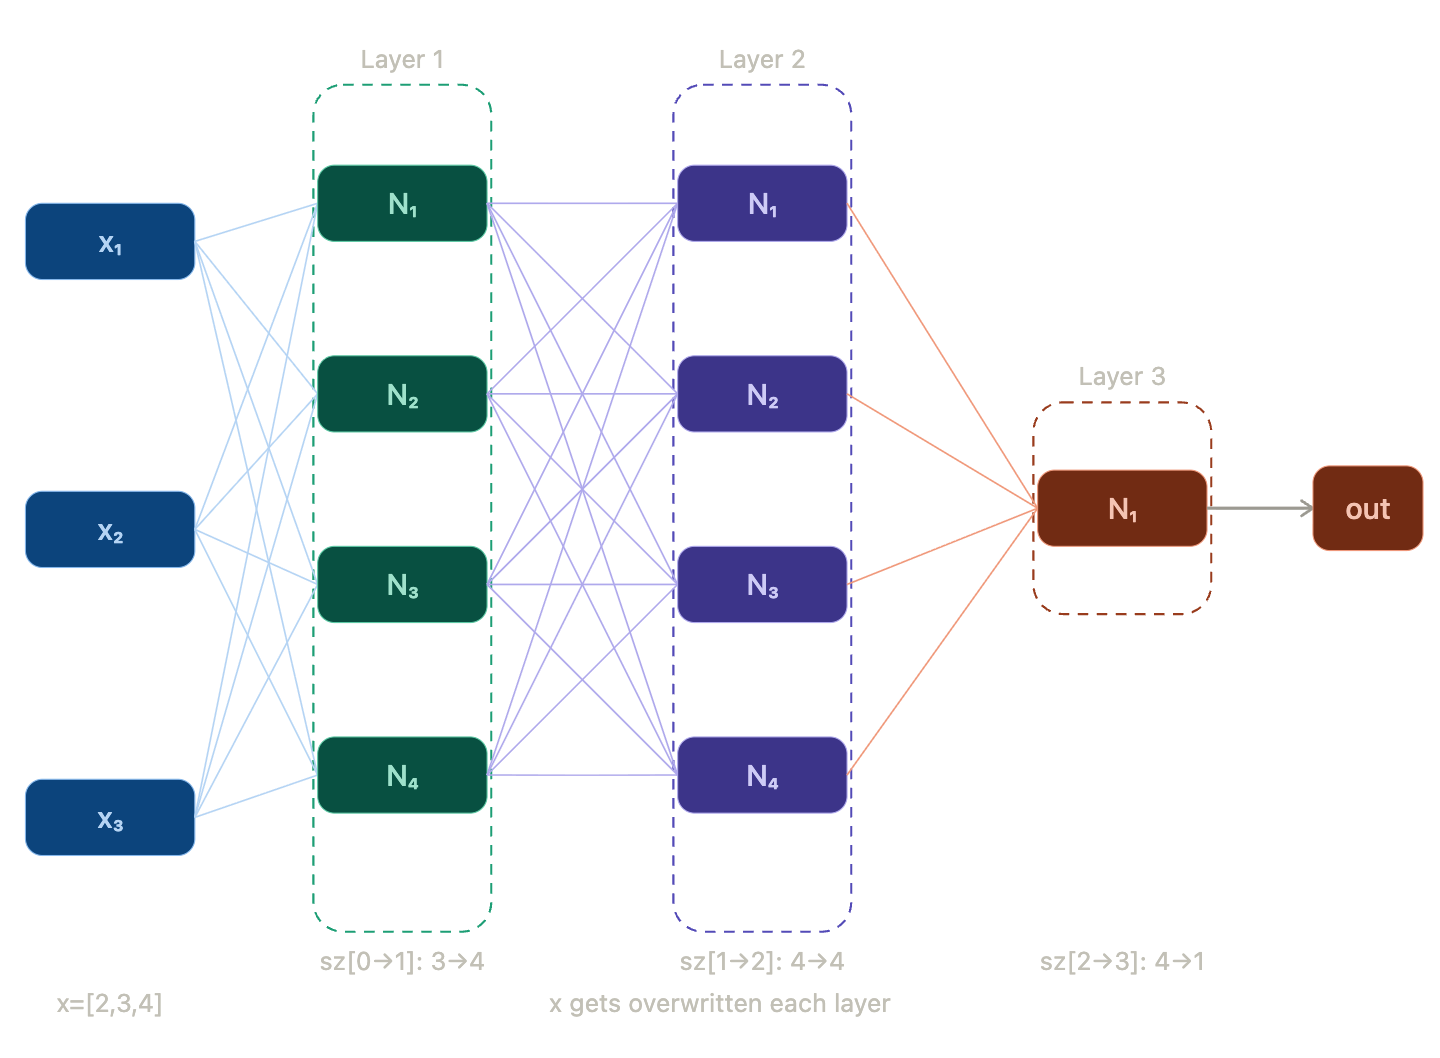

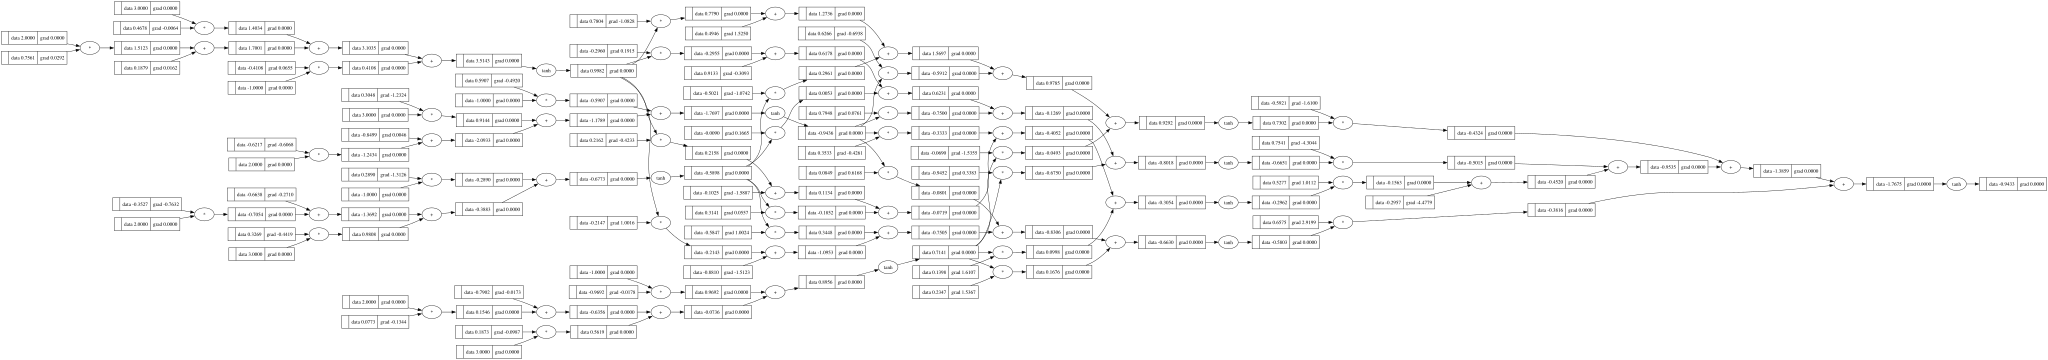

In [71]:
draw_dot(n(x))

In [84]:
# some practice 

xs = [
    [3.0, 2.0, 5.0],
    [8.0, 6.0, 1.0],
    [2.0, -1.0, -3.0],
    [-0.5, -5.0, 2.1]
]

ys = [1.0, -1.0, -1.0, 1.0] # desired outcome
ypred = [n(x) for x in xs] 
ypred

[Value(data=-0.35500121511539207),
 Value(data=-0.892197865751179),
 Value(data=-0.9424671822221261),
 Value(data=0.01726124102855051)]

As you can see the outcome of the forward pass is not close to the outcome we desired
So we need to train out Neurons for this. 

The real question is how do we tune the nueral nets to better predict the returns of the forward pass? something called the loss function

In [85]:
# Take the ys and the ground truth and subtract and sqaure them to ensure we get a positive number always
[(yout - ygt)**2 for ygt, yout in zip(ys, ypred)]

[Value(data=1.836028292964189),
 Value(data=0.011621300148600829),
 Value(data=0.003310025121462042),
 Value(data=0.9657754683847446)]

In [86]:
# So the final loss is the sum of all of these numbers: 
loss = sum([(yout - ygt)**2 for ygt, yout in zip(ys, ypred)]) 
loss

Value(data=2.816735086618996)

Now we need to minimize the loss because the lower the loss the better our model. And the way to minimize it is by doing a backward propogation

In [87]:
loss.backward()

In [88]:
n.layers[0].neurons[0].w[0].grad

0.07331717306834483

In [89]:
n.layers[0].neurons[0].w[0].data

0.7558422589389108

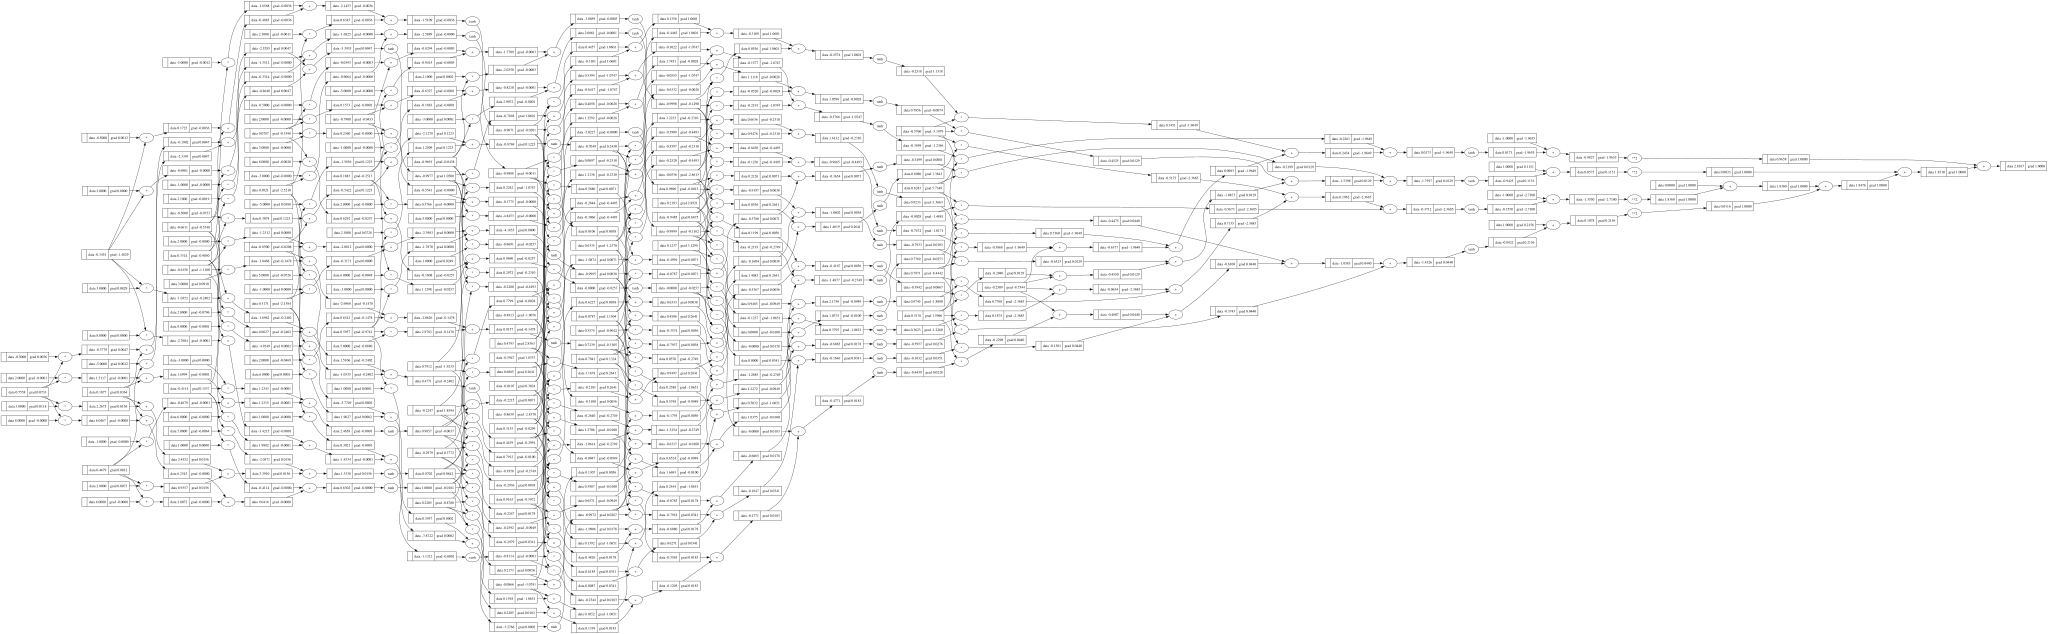

In [90]:
draw_dot(loss)

### The gradient of the input data is not very useful to us mainly because the value of the input is a given and we can't really change that 

In [91]:
# So now we can get all the weights and biases
# So in total this MLP has 41 parameters
n.parameters()

[Value(data=0.7558422589389108),
 Value(data=0.46786467535818727),
 Value(data=-0.41142790759131936),
 Value(data=0.18771791146194336),
 Value(data=-0.34505549322608803),
 Value(data=0.3313590634809633),
 Value(data=0.3021206541938064),
 Value(data=-0.6610656348584221),
 Value(data=-0.6156164215524963),
 Value(data=0.3171176966933289),
 Value(data=0.5956575877251368),
 Value(data=-0.8499875620581131),
 Value(data=0.07865279759187332),
 Value(data=0.18830301524294843),
 Value(data=-0.9690526308589273),
 Value(data=-0.7900313573056525),
 Value(data=0.22046274984356695),
 Value(data=0.31351185331912335),
 Value(data=0.3575455454401466),
 Value(data=0.12370385308095375),
 Value(data=-0.08659686147191253),
 Value(data=-0.29789395030770965),
 Value(data=-0.010696538737189842),
 Value(data=0.7940754223300629),
 Value(data=-0.9485468979712842),
 Value(data=0.9163483062358531),
 Value(data=0.7912212196354134),
 Value(data=-0.49134662920403205),
 Value(data=0.6335204524176514),
 Value(data=-0.05

In [210]:
loss.backward()

In [211]:
# Now have the loss, we need to find out how we can minimize the loss to make our prediction model more accurate 
# We do that by doing what's know as dragient descent. And this is the escence of a network learning

for p in n.parameters():
    p.data += -0.01 * p.grad


Local Sensitivity: The p.grad value is a specific number calculated for each individual parameter. If p.grad is negative, the expression -0.01 * p.grad becomes positive, which results in increasing the value of p.data. If p.grad is positive, that same formula becomes negative, which results in decreasing the value of p.data

In [212]:
n.layers[0].neurons[0].w[0].data

0.7058728948417221

In [213]:
ypred = [n(x) for x in xs] 
loss = sum([(yout - ygt)**2 for ygt, yout in zip(ys, ypred)]) 
loss

Value(data=0.0001845091104094281)

### As you can see the loss value has becom smaller thus more accurate towards the target
We can keep running the gradient descent to get the lower loss

Now you can do forward pass, backward pass, and update the parameters

In [214]:
ypred

[Value(data=0.999999365560698),
 Value(data=-0.9869347764176923),
 Value(data=-0.9962839485003917),
 Value(data=0.9999979991288019)]

In [216]:
# So this is the setting we trained
n.parameters()

[Value(data=0.7058728948417221),
 Value(data=0.4503056846450335),
 Value(data=-0.511334646943862),
 Value(data=0.16690749227979024),
 Value(data=-0.3470264601211639),
 Value(data=0.27081031679598816),
 Value(data=1.1876025169166682),
 Value(data=-0.5398358664356239),
 Value(data=-1.1634812820215878),
 Value(data=0.3248309053450267),
 Value(data=0.8617221519360114),
 Value(data=-0.9479173020489079),
 Value(data=0.9955275574106975),
 Value(data=0.8615005717448684),
 Value(data=-0.8716332545168587),
 Value(data=-0.6711388304852702),
 Value(data=0.1913002453366645),
 Value(data=0.294551417765747),
 Value(data=1.1410726893591372),
 Value(data=-1.5218157204239338),
 Value(data=0.7438749321752416),
 Value(data=-1.0456016876567218),
 Value(data=-0.24563014665663102),
 Value(data=1.287390379527139),
 Value(data=-1.7591479039217215),
 Value(data=0.566545263083728),
 Value(data=1.5604635885243188),
 Value(data=0.16981168449063086),
 Value(data=0.9344585471187355),
 Value(data=1.1359877024959213),

In [235]:
n = MLP(2, [4, 4, 1])

xs = [
    [3.0, 2.0, 5.0],
    [8.0, 6.0, 1.0],
    [2.0, -1.0, -3.0],
    [-0.5, -5.0, 2.1]
]
ys = [1.0, -1.0, -1.0, 1.0] # desired outcome

In [268]:
# Let's clean up a bit

for k in range(20):
    # forward pass : in prod people use cross entropy loss for predicting the next token 
    ypred = [n(x) for x in xs] 
    loss = sum([(yout - ygt)**2 for ygt, yout in zip(ys, ypred)]) 

    # backward pass: 
    # very commong bug: you need to reflush the grads before doing the second backward propogation
    for p in n.parameters(): 
        p.grad = 0.0
    loss.backward() 

    # gradient descent
    for p in n.parameters():
        p.data += -0.05 * p.grad

    print(k, loss.data) 

0 0.008886349604049075
1 0.00881233737542635
2 0.008739490889503942
3 0.008667783331261707
4 0.008597188693520086
5 0.008527681746941828
6 0.00845923801135465
7 0.008391833728327356
8 0.008325445834936824
9 0.008260051938665419
10 0.008195630293373139
11 0.008132159776290945
12 0.008069619865985924
13 0.008007990621249675
14 0.007947252660866431
15 0.007887387144217942
16 0.00782837575268533
17 0.007770200671810019
18 0.007712844574178035
19 0.0076562906029939565


In [269]:
ypred

[Value(data=0.9352957523962314),
 Value(data=-0.9531871432997824),
 Value(data=-0.9667049663378665),
 Value(data=0.9869750959302399)]